# Notebook 01 — MRI Preprocessing
Preprocessing pipeline for brain tumor MRI images: loading, labeling, resizing, normalization, class distribution analysis, and train/val/test splitting.


## 1. Mount Google Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive', force_remount=False)

Mounted at /content/drive


## 2. Unzip MRI Dataset to Local Colab Storage
Reading from Drive is slow. Unzipping once to /content/mri_data/ makes all reads much faster.

In [2]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/MRI/MRI.zip"
extract_path = "/content/mri_data/"

if not os.path.exists(extract_path) or len(os.listdir(extract_path)) == 0:
    print("Unzipping MRI dataset... (this may take a few minutes)")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)
    print("Done!")
else:
    print("Already unzipped, skipping.")

Unzipping MRI dataset... (this may take a few minutes)
Done!


## 3. Imports

In [3]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split

## 4. Load Image Paths and Assign Binary Labels

In [4]:
mri_path = Path("/content/mri_data/MRI")

image_files = (
    list(mri_path.rglob("*.jpg")) +
    list(mri_path.rglob("*.png")) +
    list(mri_path.rglob("*.jpeg"))
)

print("Total MRI images found:", len(image_files))

Total MRI images found: 7200


In [5]:
image_files_clean = []
labels_clean = []
skipped = []

for img_path in image_files:
    folder_name = img_path.parent.name.lower()
    if folder_name in ["glioma", "meningioma", "pituitary", "tumor"]:
        image_files_clean.append(img_path)
        labels_clean.append(1)
    elif folder_name in ["no tumor", "notumor", "normal"]:
        image_files_clean.append(img_path)
        labels_clean.append(0)
    else:
        skipped.append(str(img_path))

image_files = image_files_clean
labels = labels_clean

print(f"Total labeled images before sampling: {len(labels)}")
if skipped:
    print(f"Skipped (unknown folder): {len(skipped)} images")

# ── Limit to 100 Tumor + 100 Healthy to match CT dataset size ──────────────
import random
random.seed(42)

tumor_idx   = [i for i, l in enumerate(labels) if l == 1]
healthy_idx = [i for i, l in enumerate(labels) if l == 0]

tumor_idx_sampled   = random.sample(tumor_idx,   100)
healthy_idx_sampled = random.sample(healthy_idx, 100)

selected_idx = sorted(tumor_idx_sampled + healthy_idx_sampled)

image_files = [image_files[i] for i in selected_idx]
labels      = [labels[i]      for i in selected_idx]

print(f"Total MRI images after sampling: {len(labels)} (100 Tumor + 100 Healthy)")


Total labeled images before sampling: 7200
Total MRI images after sampling: 200 (100 Tumor + 100 Healthy)


## 5. Class Distribution

Class distribution:
  Healthy (0): 100 images
  Tumor   (1): 100 images
  Balance ratio (Tumor:Healthy): 1.00


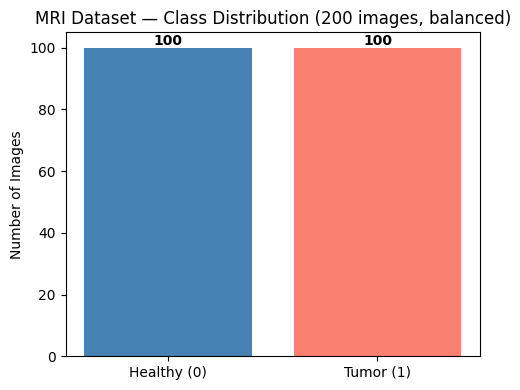

In [6]:
counts = np.bincount(labels)
print(f"Class distribution:")
print(f"  Healthy (0): {counts[0]} images")
print(f"  Tumor   (1): {counts[1]} images")
print(f"  Balance ratio (Tumor:Healthy): {counts[1]/counts[0]:.2f}")

plt.figure(figsize=(5, 4))
plt.bar(["Healthy (0)", "Tumor (1)"], counts, color=["steelblue", "salmon"])
plt.title("MRI Dataset — Class Distribution (200 images, balanced)")
plt.ylabel("Number of Images")
for i, v in enumerate(counts):
    plt.text(i, v + 1, str(v), ha='center', fontweight='bold')
plt.tight_layout()
plt.show()


## 6. Visualize a Sample Image (Raw vs Processed)

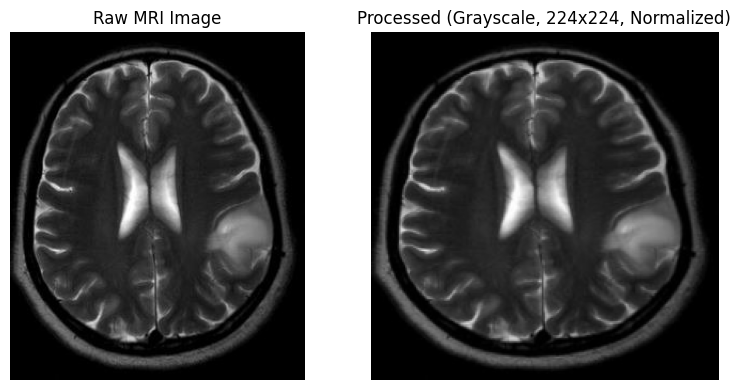

In [7]:
sample_path = image_files[0]

img_raw = cv2.imread(str(sample_path))
img_raw_rgb = cv2.cvtColor(img_raw, cv2.COLOR_BGR2RGB)

img_gray = cv2.imread(str(sample_path), cv2.IMREAD_GRAYSCALE)
img_resized = cv2.resize(img_gray, (224, 224))
img_norm = img_resized / 255.0

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.imshow(img_raw_rgb)
plt.title("Raw MRI Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(img_norm, cmap="gray")
plt.title("Processed (Grayscale, 224x224, Normalized)")
plt.axis("off")

plt.tight_layout()
plt.show()

## 7. Train / Validation / Test Split (70 / 15 / 15)
Stratified split to preserve class ratios across all sets.

In [8]:
image_files_arr = np.array(image_files, dtype=object)
labels_arr = np.array(labels)

train_paths, temp_paths, y_train, y_temp = train_test_split(
    image_files_arr, labels_arr,
    test_size=0.40,
    random_state=42,
    stratify=labels_arr
)

val_paths, test_paths, y_val, y_test = train_test_split(
    temp_paths, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print(f"Train:      {len(train_paths)} images | {np.bincount(y_train)}")
print(f"Validation: {len(val_paths)}  images | {np.bincount(y_val)}")
print(f"Test:       {len(test_paths)}  images | {np.bincount(y_test)}")


Train:      120 images | [60 60]
Validation: 40  images | [20 20]
Test:       40  images | [20 20]


## 8. Save Splits to Google Drive

In [9]:
np.savez(
    "/content/drive/MyDrive/MRI/mri_splits.npz",
    train_paths=train_paths.astype(str),
    val_paths=val_paths.astype(str),
    test_paths=test_paths.astype(str),
    y_train=y_train,
    y_val=y_val,
    y_test=y_test
)

print("Saved mri_splits.npz to Google Drive successfully.")
print("Load in other notebooks with: data = np.load('/content/drive/MyDrive/MRI/mri_splits.npz', allow_pickle=True)")

Saved mri_splits.npz to Google Drive successfully.
Load in other notebooks with: data = np.load('/content/drive/MyDrive/MRI/mri_splits.npz', allow_pickle=True)
